# Step 2: Preprocessing & Data Augmentation

This notebook implements all requirements for **Étape 2**:
1. **Stratified Data Splitting**: Creating clean `Train` (80%), `Val` (10%), and `Test` (10%) sets without data leakage.
2. **Annotation Organization & 'No Tumor' Cleaning**: Clearing fake bounding boxes from `No Tumor` for object detection.
3. **Image Resizing & Normalization**: Standardizing to $224 \times 224$ (classification) and scaling pixel intensities.
4. **Data Augmentation Pipeline**: Rotations, translations, zooms, and contrast adjustments for training.
5. **Bounding Box Adaptation**: Ensuring geometric augmentations properly transform bounding box coordinates.
6. **Deterministic Evaluation**: Ensuring validation and test data remain completely unaugmented.

In [5]:
import os
import random
import shutil
from pathlib import Path
import cv2
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Visualization setup
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)

# Directory Paths
DATA_DIR = Path('../data')
CLASSES = ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']
TRAIN_DIR = DATA_DIR / 'Train'
VAL_DIR = DATA_DIR / 'Val'
TEST_DIR = DATA_DIR / 'Test'

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Target Classes: {CLASSES}")


Data directory: /home/emad/Desktop/AI projects/IRM detection/data
Target Classes: ['Glioma', 'Meningioma', 'No Tumor', 'Pituitary']


## 1. Stratified Data Split (80% Train / 10% Val / 10% Test)
- Reverts any previous partial split back to `Val`.
- Moves ~10% (~473 images) from `Train` into `Test`.
- Keeps image files and `.txt` label files strictly paired to eliminate data leakage.

In [6]:
# 1. Deterministic seed for reproducible split
random.seed(42)

# Step 1a: Revert any files currently in Test back to Val (safely restores Val)
for cls in CLASSES:
    t_img_dir = TEST_DIR / cls / 'images'
    t_lbl_dir = TEST_DIR / cls / 'labels'
    v_img_dir = VAL_DIR / cls / 'images'
    v_lbl_dir = VAL_DIR / cls / 'labels'
    
    if t_img_dir.exists():
        for img in t_img_dir.glob('*'):
            shutil.move(str(img), str(v_img_dir / img.name))
    if t_lbl_dir.exists():
        for lbl in t_lbl_dir.glob('*.txt'):
            shutil.move(str(lbl), str(v_lbl_dir / lbl.name))

# Clean up temporary Test directory
shutil.rmtree(TEST_DIR, ignore_errors=True)

# Step 1b: Take ~10% from Train to create the new Test set (~473 images)
for cls in CLASSES:
    train_img_dir = TRAIN_DIR / cls / 'images'
    train_lbl_dir = TRAIN_DIR / cls / 'labels'
    
    test_img_dir = TEST_DIR / cls / 'images'
    test_lbl_dir = TEST_DIR / cls / 'labels'
    
    test_img_dir.mkdir(parents=True, exist_ok=True)
    test_lbl_dir.mkdir(parents=True, exist_ok=True)
    
    images = [f for f in train_img_dir.glob('*') if f.suffix.lower() in ['.jpg', '.jpeg', '.png']]
    random.shuffle(images)
    
    # Extract 10% of this class from Train
    num_to_test = int(len(images) * 0.10)
    test_images = images[:num_to_test]
    
    for img_path in test_images:
        shutil.move(str(img_path), str(test_img_dir / img_path.name))
        
        lbl_path = train_lbl_dir / f"{img_path.stem}.txt"
        if lbl_path.exists():
            shutil.move(str(lbl_path), str(test_lbl_dir / lbl_path.name))

# Step 1c: Print final count verification
final_counts = []
for cls in CLASSES:
    tr_cnt = len(list((TRAIN_DIR / cls / 'images').glob('*')))
    val_cnt = len(list((VAL_DIR / cls / 'images').glob('*')))
    ts_cnt = len(list((TEST_DIR / cls / 'images').glob('*')))
    final_counts.append({
        'Class': cls,
        'Train (80%)': tr_cnt,
        'Val (10%)': val_cnt,
        'Test (10%)': ts_cnt,
        'Total': tr_cnt + val_cnt + ts_cnt
    })

print("=== Final 80 / 10 / 10 Dataset Split ===")
display(pd.DataFrame(final_counts))


=== Final 80 / 10 / 10 Dataset Split ===


,Class,Train (80%),Val (10%),Test (10%),Total
0,Glioma,935,251,103,1289
1,Meningioma,1175,284,130,1589
2,No Tumor,576,171,64,811
3,Pituitary,1154,278,128,1560


## 2. Clean 'No Tumor' Labels for Object Detection
- Empty all `.txt` files in `No Tumor/labels/` (0 bytes).
- Transforms healthy scans into background (negative) samples for YOLO.

In [7]:
from pathlib import Path

DATA_DIR = Path('../data')
SPLITS = ['Train', 'Val', 'Test']

total_cleaned = 0

for split in SPLITS:
    no_tumor_lbl_dir = DATA_DIR / split / 'No Tumor' / 'labels'
    
    if no_tumor_lbl_dir.exists():
        for txt_file in no_tumor_lbl_dir.glob('*.txt'):
            # Overwrite with empty string (0 bytes)
            txt_file.write_text('')
            total_cleaned += 1

print(f"=== Successfully emptied {total_cleaned} 'No Tumor' label files! ===")

# Quick Verification: check that all file sizes are 0 bytes
non_zero = [f.name for split in SPLITS 
            for f in (DATA_DIR / split / 'No Tumor' / 'labels').glob('*.txt') 
            if f.stat().st_size > 0]

print(f"Files with size > 0 bytes: {len(non_zero)} (Should be 0)")

=== Successfully emptied 811 'No Tumor' label files! ===
Files with size > 0 bytes: 0 (Should be 0)


## 3.1 Constants & Configuration

In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)

BATCH_SIZE = 32



## 3.2 Loading Datasets from Directories

In [ ]:
train_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR / 'Train' , image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=True)

val_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR / 'Val' , image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False)

test_ds = tf.keras.utils.image_dataset_from_directory(DATA_DIR / 'Test' , image_size=IMG_SIZE, batch_size=BATCH_SIZE, label_mode='categorical', shuffle=False)


Found 3840 files belonging to 4 classes.
Found 984 files belonging to 4 classes.
Found 425 files belonging to 4 classes.


E0000 00:00:1792664896.299624   11982 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: ===
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## 3.3 Data Augmentation Pipeline

In [11]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    tf.keras.layers.RandomContrast(0.1)
])

## 3.4 Visualizing Data Augmentation on a Sample MRI

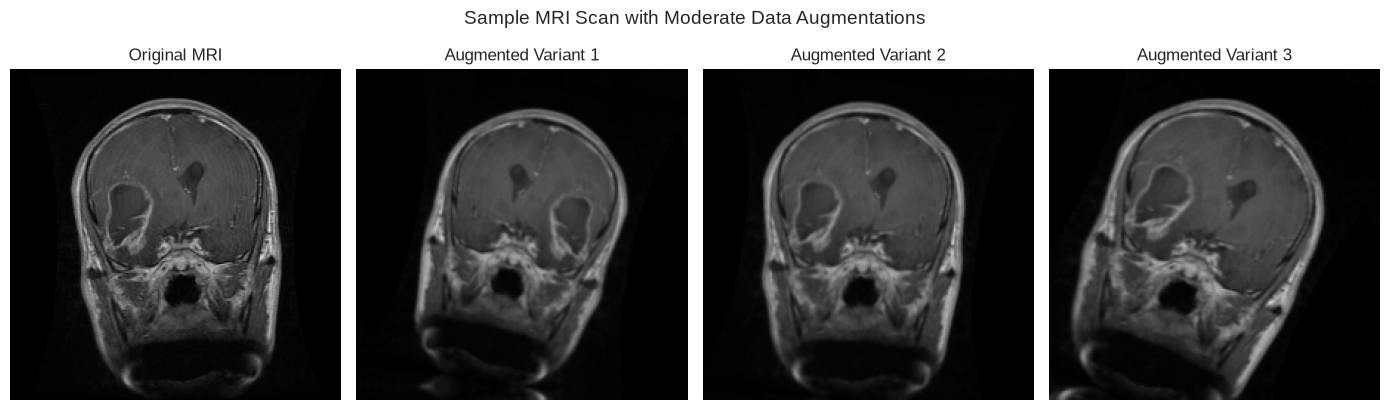

In [13]:
for images, labels in train_ds.take(1):
    first_image = images[0]
    break

plt.figure(figsize=(14, 4))

# Display Original Image
plt.subplot(1, 4, 1)
plt.imshow(first_image.numpy().astype("uint8"))
plt.title("Original MRI", fontsize=12)
plt.axis("off")

# Display 3 Augmented Variants of the same MRI
for i in range(1, 4):
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.subplot(1, 4, i + 1)
    plt.imshow(augmented_image[0].numpy().astype("uint8"))
    plt.title(f"Augmented Variant {i}", fontsize=12)
    plt.axis("off")

plt.suptitle("Sample MRI Scan with Moderate Data Augmentations", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()


## 3.5 Performance Optimization (AUTOTUNE Prefetching)

In [16]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("dataset configured with AUTOTUNE")

dataset configured with AUTOTUNE


## 4. Adapting Bounding Boxes to Geometric Transformations (Detection)
- In object detection, transforming an image requires recalculating bounding box coordinates.
- For a horizontal flip: x_new = 1.0 - x_old (y, width, height remain identical).

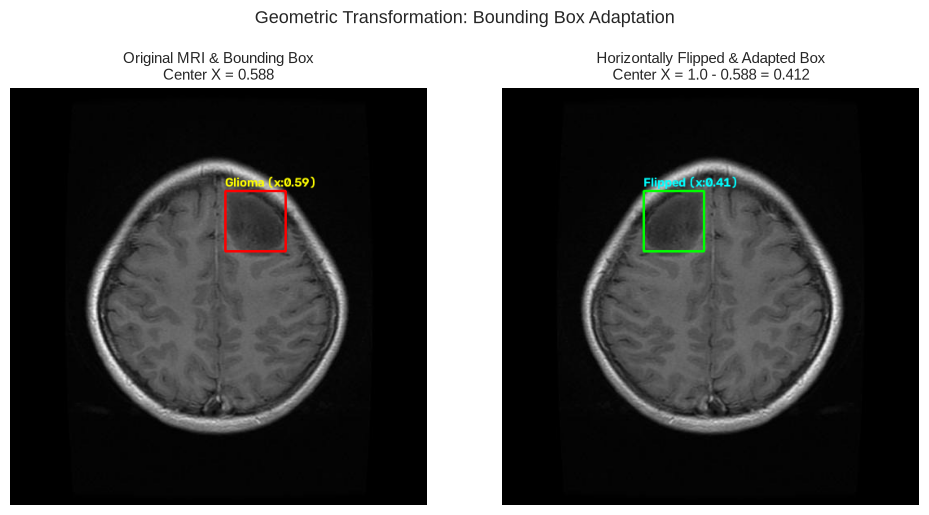

In [17]:
# Helper to convert normalized YOLO (xc, yc, w, h) to pixel box (xmin, ymin, xmax, ymax)
def yolo_to_pixel(xc, yc, w, h, img_w, img_h):
    xmin = int((xc - w / 2) * img_w)
    ymin = int((yc - h / 2) * img_h)
    xmax = int((xc + w / 2) * img_w)
    ymax = int((yc + h / 2) * img_h)
    return max(0, xmin), max(0, ymin), min(img_w, xmax), min(img_h, ymax)

# Pick a sample Glioma image and label
sample_img_path = sorted(list((DATA_DIR / 'Train' / 'Glioma' / 'images').glob('*')))[0]
sample_lbl_path = DATA_DIR / 'Train' / 'Glioma' / 'labels' / f"{sample_img_path.stem}.txt"

# Load original image
img_orig = cv2.imread(str(sample_img_path))
img_orig = cv2.cvtColor(img_orig, cv2.COLOR_BGR2RGB)
h, w, _ = img_orig.shape

# Read original bounding box coordinates
with open(sample_lbl_path, 'r') as f:
    line = f.readline().strip().split()
    cls_id, xc, yc, bw, bh = int(line[0]), float(line[1]), float(line[2]), float(line[3]), float(line[4])

# Apply Horizontal Flip to Image AND Coordinate
img_flipped = cv2.flip(img_orig, 1)  # Horizontal flip
xc_flipped = 1.0 - xc                 # Geometric adaptation: x_new = 1.0 - x_old
yc_flipped, bw_flipped, bh_flipped = yc, bw, bh

# Draw bounding box on both
# Original (Red box)
x1, y1, x2, y2 = yolo_to_pixel(xc, yc, bw, bh, w, h)
img_orig_box = img_orig.copy()
cv2.rectangle(img_orig_box, (x1, y1), (x2, y2), (255, 0, 0), 2)
cv2.putText(img_orig_box, f"Glioma (x:{xc:.2f})", (x1, max(15, y1 - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 255, 0), 2)

# Flipped (Green box)
x1_f, y1_f, x2_f, y2_f = yolo_to_pixel(xc_flipped, yc_flipped, bw_flipped, bh_flipped, w, h)
img_flipped_box = img_flipped.copy()
cv2.rectangle(img_flipped_box, (x1_f, y1_f), (x2_f, y2_f), (0, 255, 0), 2)
cv2.putText(img_flipped_box, f"Flipped (x:{xc_flipped:.2f})", (x1_f, max(15, y1_f - 5)), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 255), 2)

# 6. Plot side by side
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(img_orig_box)
plt.title(f"Original MRI & Bounding Box\nCenter X = {xc:.3f}", fontsize=11)
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_flipped_box)
plt.title(f"Horizontally Flipped & Adapted Box\nCenter X = 1.0 - {xc:.3f} = {xc_flipped:.3f}", fontsize=11)
plt.axis('off')

plt.suptitle("Geometric Transformation: Bounding Box Adaptation", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
